# Эксперимент: Growing Neural Gas (GNG) и адаптация топологии


**Цель этого эксперимента:** Продемонстрировать свойство непрерывного обучения (Continuous Learning). Мы создадим **один** экземпляр сети GNG и последовательно "скормим" ему три разных датасета (луны, окружности и блобы). Сеть будет адаптироваться, перестраивая свою топологию под новые данные.

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons, make_circles, make_blobs
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import adjusted_rand_score
import warnings

warnings.filterwarnings('ignore')

plt.style.use('ggplot')

In [16]:
class GrowingNeuralGas:
    def __init__(self, max_nodes=120, epsilon_b=0.2, epsilon_n=0.006, 
                 lambda_=500, alpha=0.5, beta=0.0005, a_max=88):
        self.max_nodes = max_nodes
        self.epsilon_b = epsilon_b
        self.epsilon_n = epsilon_n
        self.lambda_ = lambda_
        self.alpha = alpha
        self.beta = beta
        self.a_max = a_max
        
        self.nodes = []
        self.errors = []
        self.edges = {} 

    def reset(self):
        """Полностью сбрасывает сеть. 
        При следующем вызове fit() сеть инициализируется заново с 2 узлов."""
        self.nodes = []
        self.errors = []
        self.edges = {}
        print("Сеть GNG сброшена. Следующий вызов fit() начнется с 2 узлов.")
        
    def _add_edge(self, i, j):
        if i not in self.edges: self.edges[i] = {}
        if j not in self.edges: self.edges[j] = {}
        self.edges[i][j] = 0
        self.edges[j][i] = 0

    def _remove_edge(self, i, j):
        if i in self.edges and j in self.edges[i]:
            del self.edges[i][j]
        if j in self.edges and i in self.edges[j]:
            del self.edges[j][i]
            
    def fit(self, X, max_iter=10000):
        if not self.nodes:
            idx = np.random.choice(len(X), 2, replace=False)
            self.nodes = [X[idx[0]].copy(), X[idx[1]].copy()]
            self.errors = [0.0, 0.0]
            self.edges = {0: {}, 1: {}}
        else:
            self.errors = [e * 0.5 for e in self.errors]
        
        for step in range(max_iter):
            x = X[np.random.randint(len(X))]
            dists = np.linalg.norm(np.array(self.nodes) - x, axis=1)
            s1 = np.argmin(dists)
            s2 = np.argsort(dists)[1]
            
            self._add_edge(s1, s2)
            self.errors[s1] += dists[s1]**2
            
            self.nodes[s1] += self.epsilon_b * (x - self.nodes[s1])
            for neighbor in list(self.edges[s1].keys()):
                self.nodes[neighbor] += self.epsilon_n * (x - self.nodes[neighbor])
                
            for neighbor in self.edges[s1]:
                self.edges[s1][neighbor] += 1
                
            for neighbor in list(self.edges[s1].keys()):
                if self.edges[s1][neighbor] > self.a_max:
                    self._remove_edge(s1, neighbor)
            
            if step % self.lambda_ == 0 and len(self.nodes) < self.max_nodes:
                q = np.argmax(self.errors)
                if q in self.edges and len(self.edges[q]) > 0:
                    f = max(self.edges[q].keys(), key=lambda k: self.errors[k])
                    r = len(self.nodes)
                    self.nodes.append((self.nodes[q] + self.nodes[f]) / 2.0)
                    self.errors.append(0.0)
                    self.edges[r] = {}
                    
                    self._add_edge(r, q)
                    self._add_edge(r, f)
                    self._remove_edge(q, f)
                    
                    self.errors[q] *= (1 - self.alpha)
                    self.errors[f] *= (1 - self.alpha)
                    self.errors[r] = self.errors[q] 
                    
            self.errors = [e * (1 - self.beta) for e in self.errors]

    def predict(self, X):
        nodes = np.array(self.nodes)
        predictions = []
        for x in X:
            dists = np.linalg.norm(nodes - x, axis=1)
            predictions.append(np.argmin(dists))
        return np.array(predictions)

In [18]:
X_moons, y_moons = make_moons(n_samples=600, noise=0.08, random_state=42)
X_circles, y_circles = make_circles(n_samples=600, factor=0.5, noise=0.05, random_state=42)
X_blobs, y_blobs = make_blobs(n_samples=600, centers=3, n_features=2, cluster_std=[0.5, 1.5, 0.8], random_state=42)

datasets = [
    ("Make Moons", X_moons, y_moons, 0.15),
    ("Make Circles", X_circles, y_circles, 0.15),
    ("Make Blobs (3 класса)", X_blobs, y_blobs, 0.6)
]

gng_model = GrowingNeuralGas(max_nodes=120)

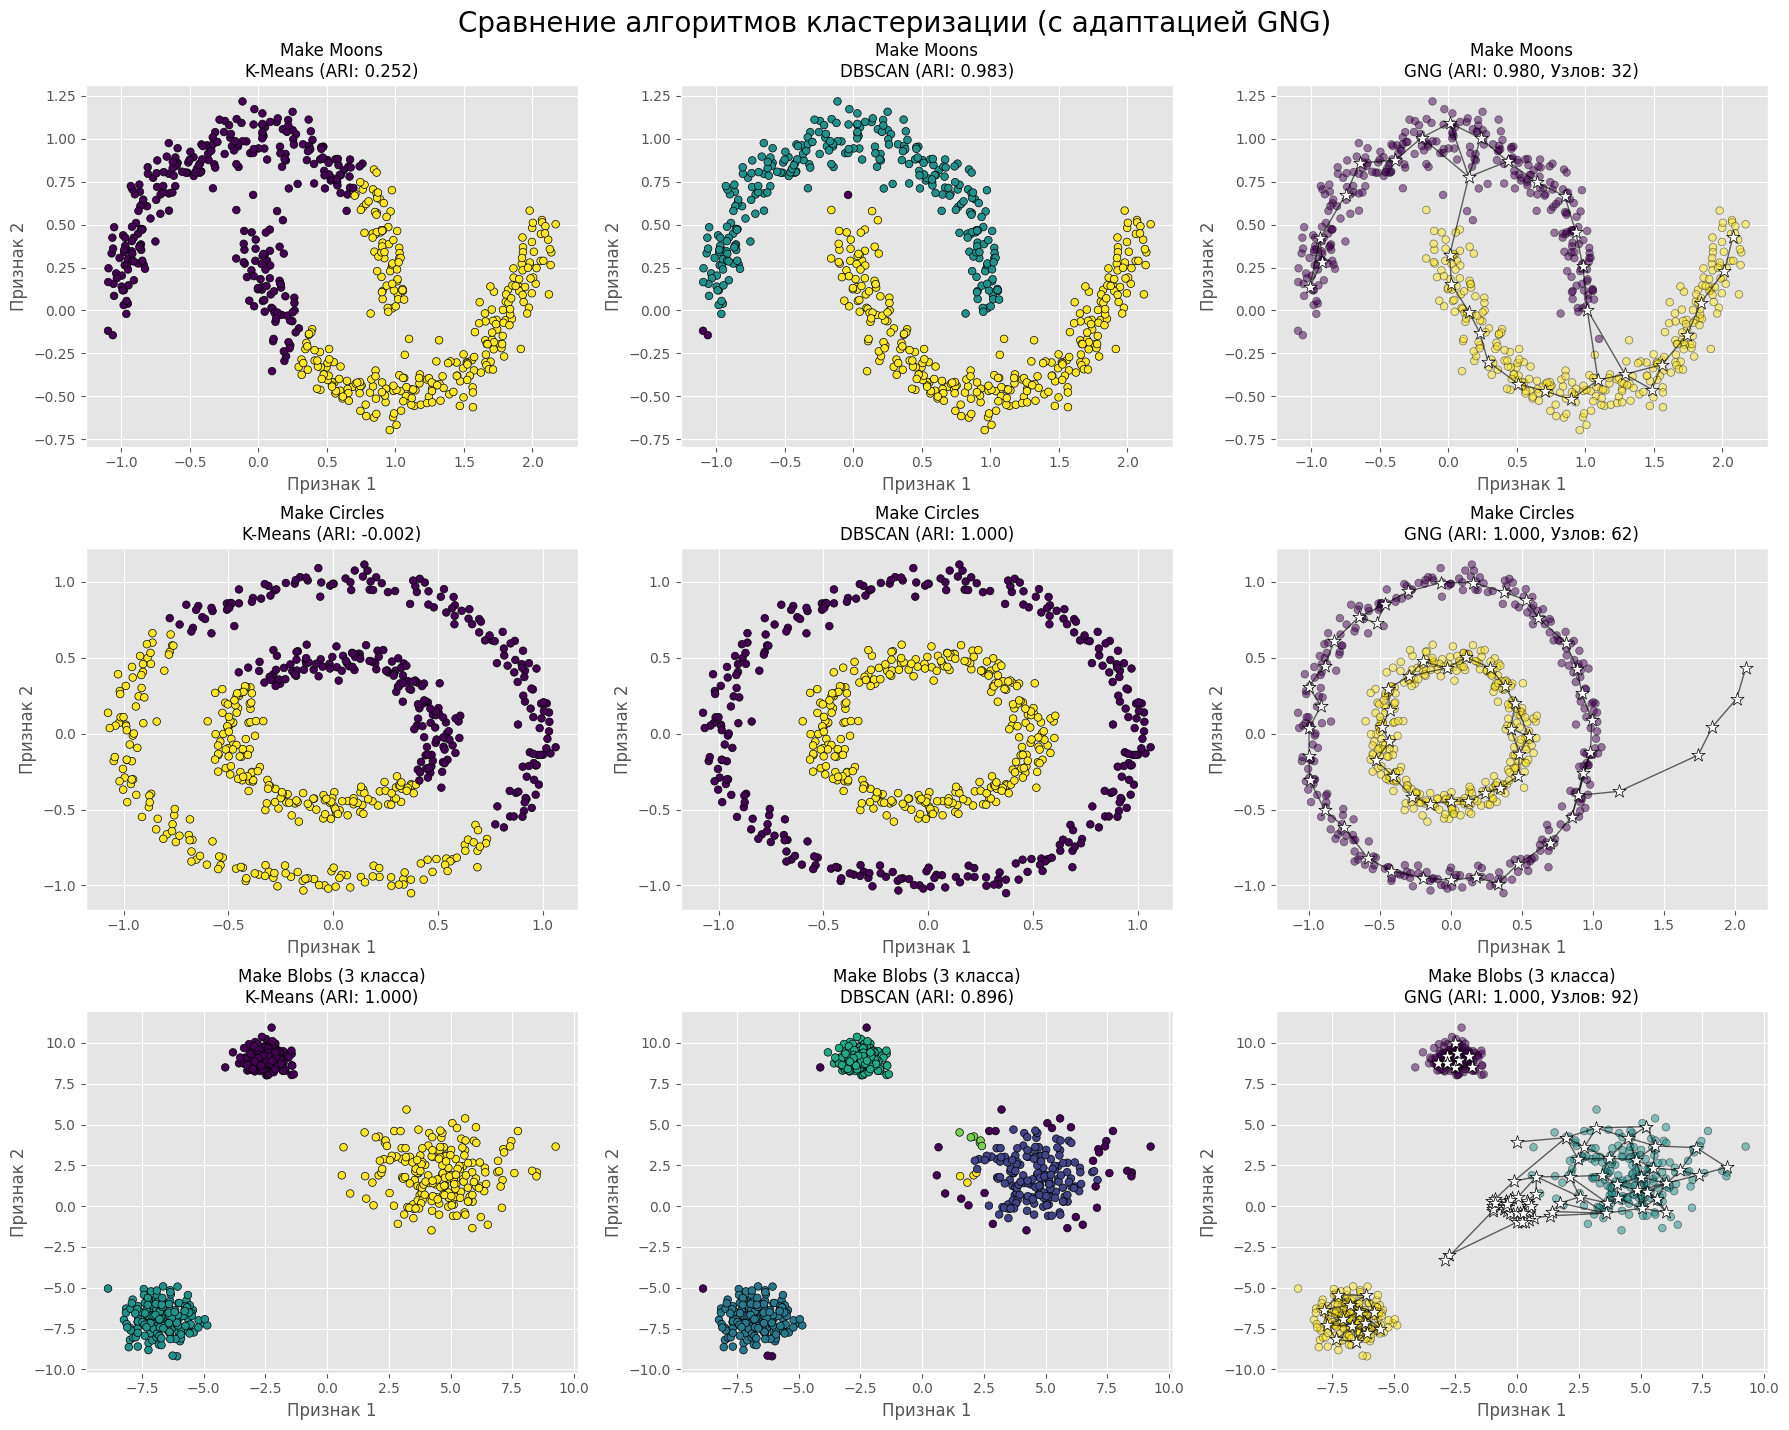

In [20]:
fig, axes = plt.subplots(3, 3, figsize=(18, 15))
fig.suptitle('Сравнение алгоритмов кластеризации (с адаптацией GNG)', fontsize=20, y=0.95)

for i, (title, X, y, eps) in enumerate(datasets):
    n_clusters = len(np.unique(y))
    
    kmeans = KMeans(n_clusters=n_clusters, random_state=42)
    kmeans_labels = kmeans.fit_predict(X)
    kmeans_ari = adjusted_rand_score(y, kmeans_labels)
    
    axes[i, 0].scatter(X[:, 0], X[:, 1], c=kmeans_labels, cmap='viridis', edgecolor='k', s=30)
    axes[i, 0].set_title(f"{title}\nK-Means (ARI: {kmeans_ari:.3f})", fontsize=12)
    
    dbscan = DBSCAN(eps=eps, min_samples=5)
    dbscan_labels = dbscan.fit_predict(X)
    dbscan_ari = adjusted_rand_score(y, dbscan_labels)
    
    db_colors = np.where(dbscan_labels == -1, -1, dbscan_labels)
    axes[i, 1].scatter(X[:, 0], X[:, 1], c=db_colors, cmap='viridis', edgecolor='k', s=30)
    axes[i, 1].set_title(f"{title}\nDBSCAN (ARI: {dbscan_ari:.3f})", fontsize=12)
    
    gng_model.fit(X, max_iter=15000)
    node_assignments = gng_model.predict(X)
    
    gng_labels = np.zeros(len(X))
    for node_idx in np.unique(node_assignments):
        mask = (node_assignments == node_idx)
        if np.sum(mask) > 0:
            majority_class = np.bincount(y[mask]).argmax()
            gng_labels[mask] = majority_class
            
    gng_ari = adjusted_rand_score(y, gng_labels)
    
    axes[i, 2].scatter(X[:, 0], X[:, 1], c=gng_labels, cmap='viridis', alpha=0.5, edgecolor='k', s=30)
    
    gng_nodes = np.array(gng_model.nodes)
    axes[i, 2].scatter(gng_nodes[:, 0], gng_nodes[:, 1], c='white', edgecolor='black', marker='*', s=100, zorder=5)
    
    for n1 in gng_model.edges:
        for n2 in gng_model.edges[n1]:
            if n1 < n2: 
                axes[i, 2].plot([gng_model.nodes[n1][0], gng_model.nodes[n2][0]], 
                                [gng_model.nodes[n1][1], gng_model.nodes[n2][1]], 
                                'k-', linewidth=1, alpha=0.6)
                                
    axes[i, 2].set_title(f"{title}\nGNG (ARI: {gng_ari:.3f}, Узлов: {len(gng_model.nodes)})", fontsize=12)

    for j in range(3):
        axes[i, j].set_xlabel("Признак 1")
        axes[i, j].set_ylabel("Признак 2")

plt.tight_layout()
plt.subplots_adjust(top=0.9)
plt.show()

Вызовем GNG ещё раз для тех же датасетов

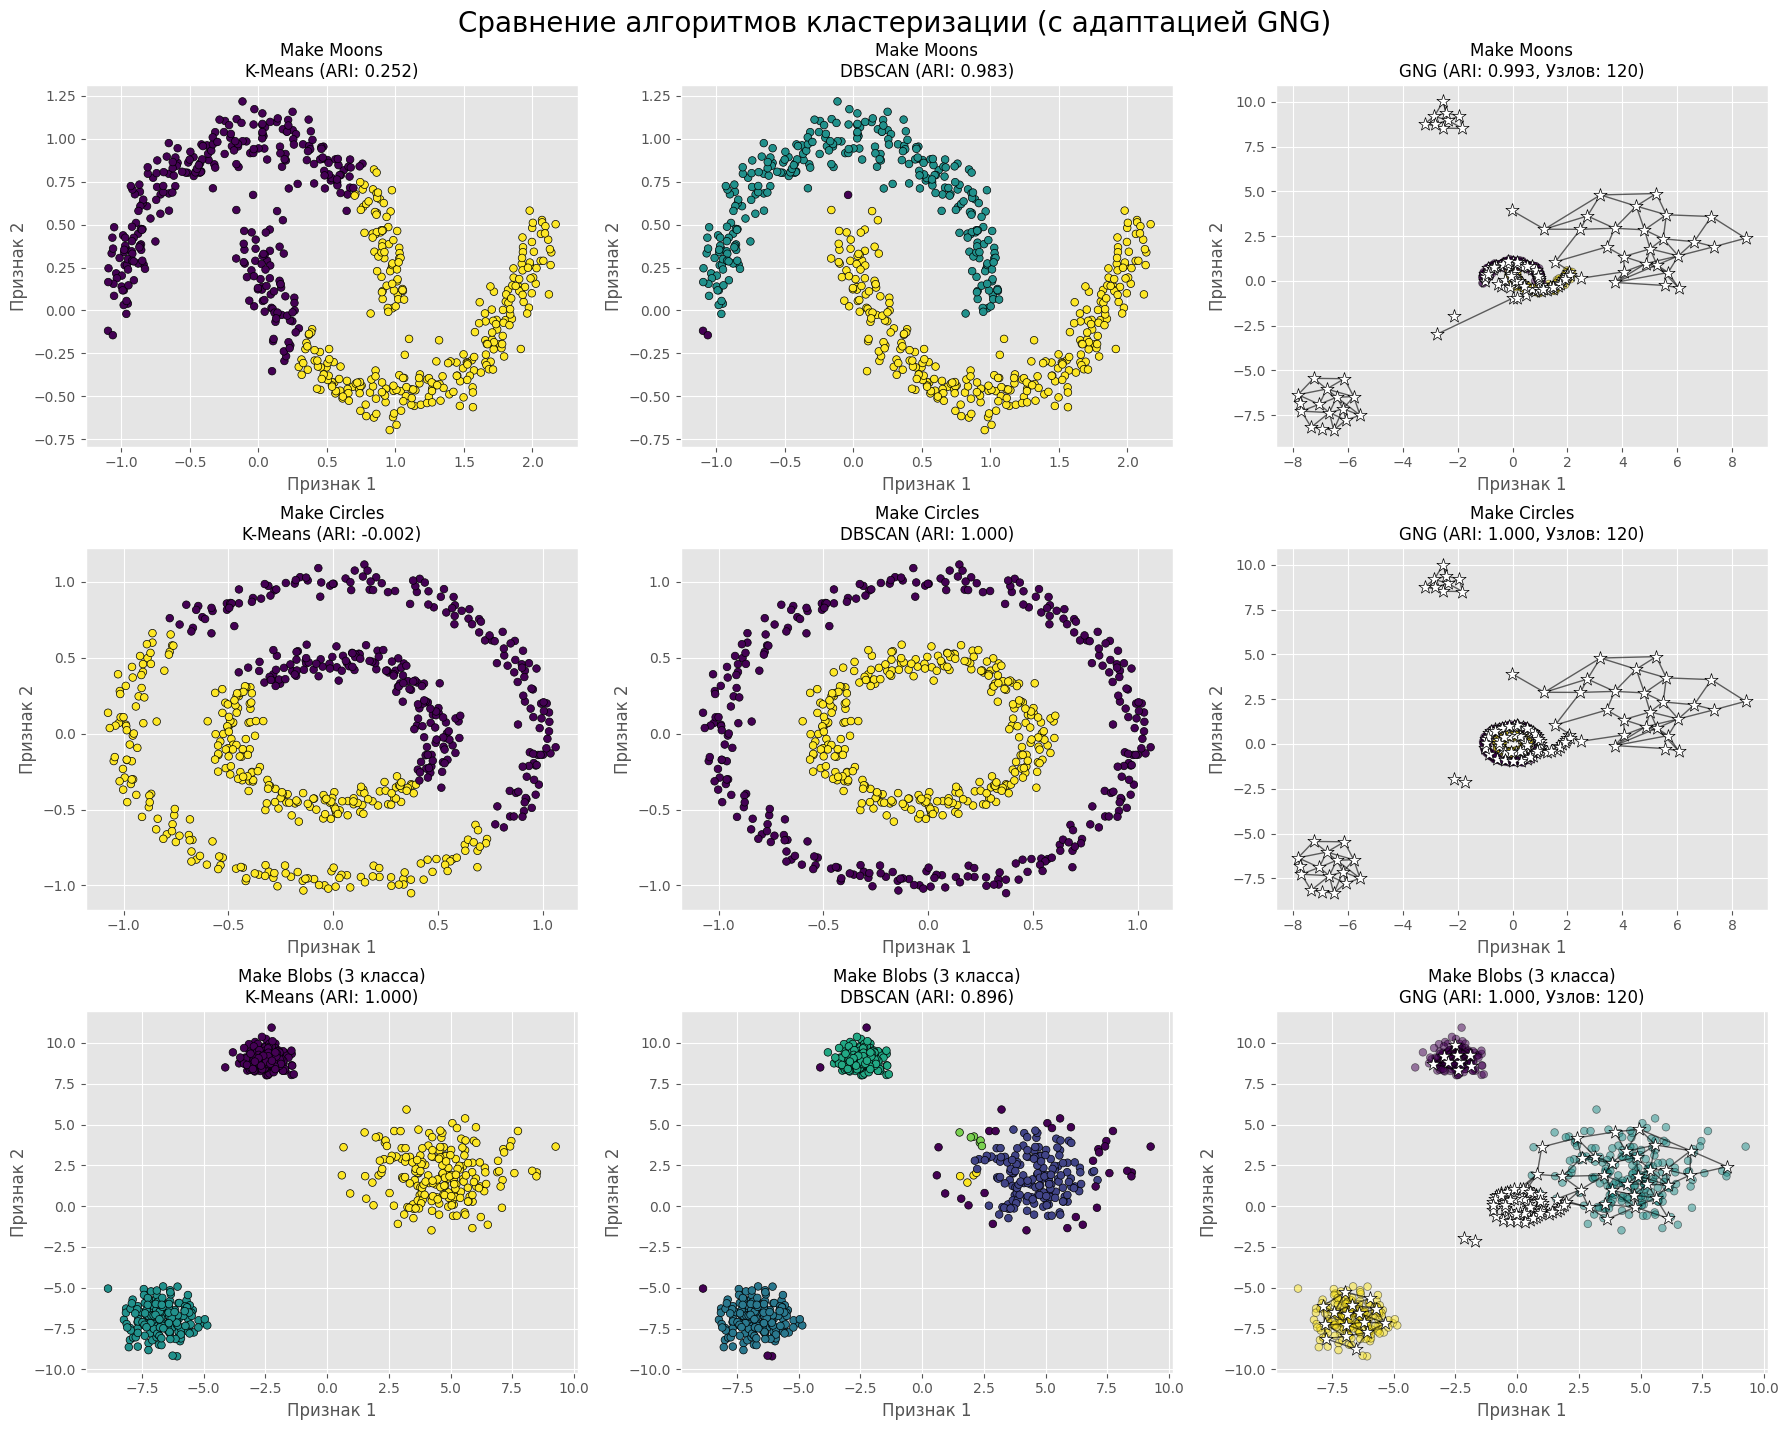

In [22]:
fig, axes = plt.subplots(3, 3, figsize=(18, 15))
fig.suptitle('Сравнение алгоритмов кластеризации (с адаптацией GNG)', fontsize=20, y=0.95)

for i, (title, X, y, eps) in enumerate(datasets):
    n_clusters = len(np.unique(y))
    
    kmeans = KMeans(n_clusters=n_clusters, random_state=42)
    kmeans_labels = kmeans.fit_predict(X)
    kmeans_ari = adjusted_rand_score(y, kmeans_labels)
    
    axes[i, 0].scatter(X[:, 0], X[:, 1], c=kmeans_labels, cmap='viridis', edgecolor='k', s=30)
    axes[i, 0].set_title(f"{title}\nK-Means (ARI: {kmeans_ari:.3f})", fontsize=12)

    dbscan = DBSCAN(eps=eps, min_samples=5)
    dbscan_labels = dbscan.fit_predict(X)
    dbscan_ari = adjusted_rand_score(y, dbscan_labels)

    db_colors = np.where(dbscan_labels == -1, -1, dbscan_labels)
    axes[i, 1].scatter(X[:, 0], X[:, 1], c=db_colors, cmap='viridis', edgecolor='k', s=30)
    axes[i, 1].set_title(f"{title}\nDBSCAN (ARI: {dbscan_ari:.3f})", fontsize=12)

    gng_model.fit(X, max_iter=15000)
    node_assignments = gng_model.predict(X)
    
    gng_labels = np.zeros(len(X))
    for node_idx in np.unique(node_assignments):
        mask = (node_assignments == node_idx)
        if np.sum(mask) > 0:
            majority_class = np.bincount(y[mask]).argmax()
            gng_labels[mask] = majority_class
            
    gng_ari = adjusted_rand_score(y, gng_labels)
    
    axes[i, 2].scatter(X[:, 0], X[:, 1], c=gng_labels, cmap='viridis', alpha=0.5, edgecolor='k', s=30)
    
    gng_nodes = np.array(gng_model.nodes)
    axes[i, 2].scatter(gng_nodes[:, 0], gng_nodes[:, 1], c='white', edgecolor='black', marker='*', s=100, zorder=5)
    
    for n1 in gng_model.edges:
        for n2 in gng_model.edges[n1]:
            if n1 < n2: 
                axes[i, 2].plot([gng_model.nodes[n1][0], gng_model.nodes[n2][0]], 
                                [gng_model.nodes[n1][1], gng_model.nodes[n2][1]], 
                                'k-', linewidth=1, alpha=0.6)
                                
    axes[i, 2].set_title(f"{title}\nGNG (ARI: {gng_ari:.3f}, Узлов: {len(gng_model.nodes)})", fontsize=12)

    for j in range(3):
        axes[i, j].set_xlabel("Признак 1")
        axes[i, j].set_ylabel("Признак 2")

plt.tight_layout()
plt.subplots_adjust(top=0.9) 
plt.show()

Вернуть GNG к исходному состоянию

In [27]:
gng_model.reset()

Сеть GNG сброшена. Следующий вызов fit() начнется с 2 узлов.


# Выводы
1) GNG отлично справляется с нелинейными структурами, точно аппроксимирует форму данных и строит топологию
2) Классический GNG не подходит для последовательного поступления новых данных. Сеть быстр успирается в лимит узлов и накапливает мертвые нейроны от старых задач и перестаёт адаптироваться к новым
3) Для работы с нестационарными потоками данных требуется GNG-U